# 01 – Exploratory Data Analysis
Goal: understand the data, check data quality, and find which customers churn.

## Key findings (summary)
1. **Imbalanced target:** 26.5% of customers churned → accuracy alone is misleading.
2. **Contract is the strongest signal:** month-to-month customers churn at 43% vs 3% on two-year contracts.
3. **New customers are the highest risk:** 52.9% churn in the first 6 months vs 9.5% after 4+ years.
4. **Expensive plans churn more:** fiber optic customers (42%) and customers paying $70–$105/month churn the most.
5. **Data quality:** 11 blank `TotalCharges` values (all new customers, tenure = 0) were filled with 0.

Next step: leakage audit before modeling

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()
df.info()

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


In [17]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [18]:
blank = df["TotalCharges"].str.strip() == ""
print("Blank TotalCharges:", blank.sum())

df.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [19]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print(df["TotalCharges"].dtype)
print("Missing now:", df["TotalCharges"].isna().sum())

float64
Missing now: 0


In [20]:
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

df["churn_flag"] = (df["Churn"] == "Yes").astype(int)
df["churn_flag"].value_counts()

Duplicate customer IDs: 0


churn_flag
0    5174
1    1869
Name: count, dtype: int64

### Data quality findings
- 7,043 customers, 21 columns, no duplicate customer IDs, no visible missing values
- `TotalCharges` was stored as text because 11 rows contained a blank space
- All 11 have tenure = 0 → new customers who haven't been billed yet, so TotalCharges = 0 is the true value
- All 11 also have Churn = No — they're too new to have churned. Only 0.16% of the data, so kept them, but in a real project I'd consider excluding brand-new customers from training
- Target: 26.5% churn (1,869 of 7,043) → imbalanced classes

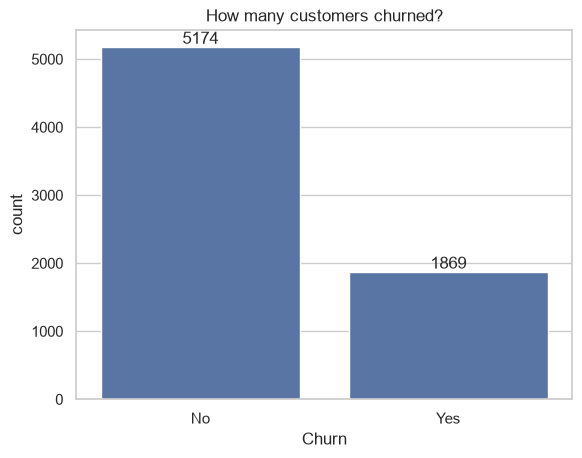

In [21]:
ax = sns.countplot(data=df, x="Churn")
ax.set_title("How many customers churned?")
ax.bar_label(ax.containers[0])
plt.show()

In [22]:
df.groupby("Contract")["churn_flag"].mean().sort_values(ascending=False)

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: churn_flag, dtype: float64

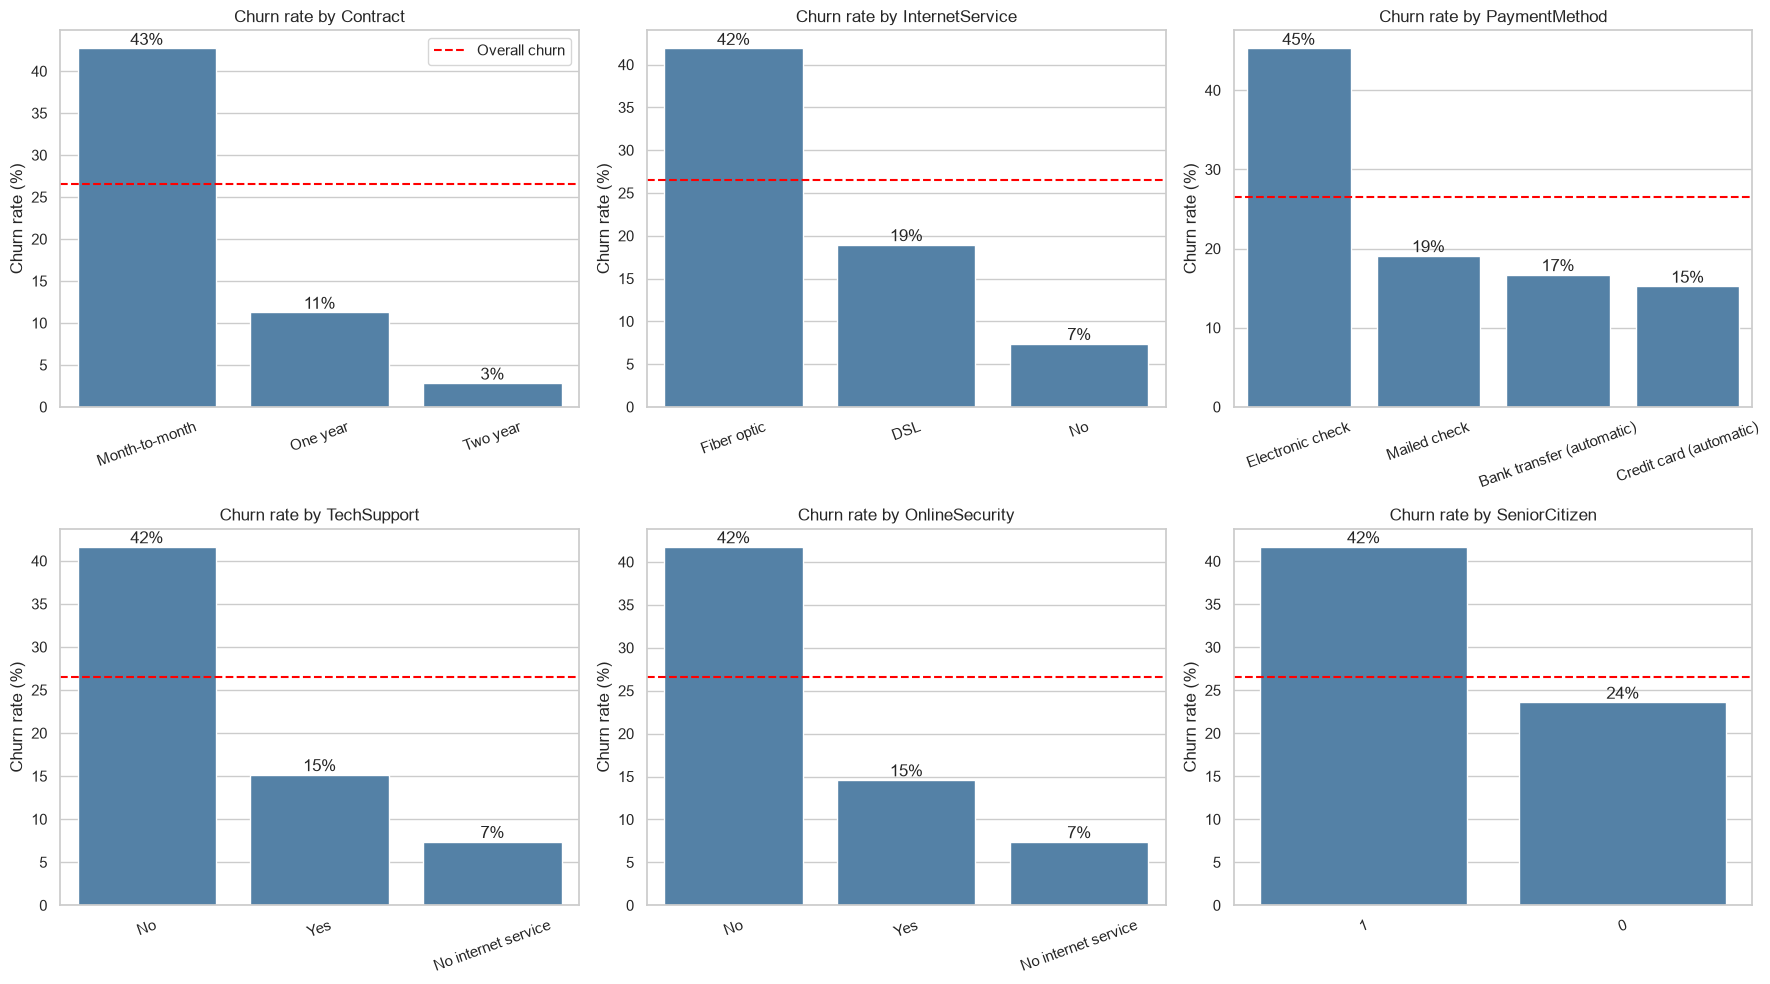

In [23]:
def plot_churn_rate(col, ax):
    rates = df.groupby(col)["churn_flag"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, color="steelblue")
    ax.axhline(df["churn_flag"].mean() * 100, color="red", linestyle="--", label="Overall churn")
    ax.bar_label(ax.containers[0], fmt="%.0f%%")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)

cols = ["Contract", "InternetService", "PaymentMethod",
        "TechSupport", "OnlineSecurity", "SeniorCitizen"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for col, ax in zip(cols, axes.flatten()):
    plot_churn_rate(col, ax)

axes[0, 0].legend()
plt.tight_layout()
plt.show()

### Who churns? (categorical features)
- InternetService: Fiber optic customers churn at 42% compared with 19%for DSL customers and 7% for customers without internet service. This might be because fiber optic customers have higher expectations for internet speed and quality so they may switch providers if they are dissatisfied.

- PaymentMethod: Customers who use electronic checks churn at 45% compared with 19% for mailed checks 17% for bank transfers and 15% for credit cards. This might be because electronic check payments are less convenient or these customers are more likely to have month-to-month contracts.

- TechSupport: Customers without tech support churn at 42% compared with 15% for customers who have tech support. This might be because customers without technical assistance have more difficulty solving internet or service problems making them more likely to leave.

- SeniorCitizen: Senior customers (1) churn at 42% compared with 24% for non-senior customers (0). This might be because senior customers may have different service needs or may be less satisfied with the available services.

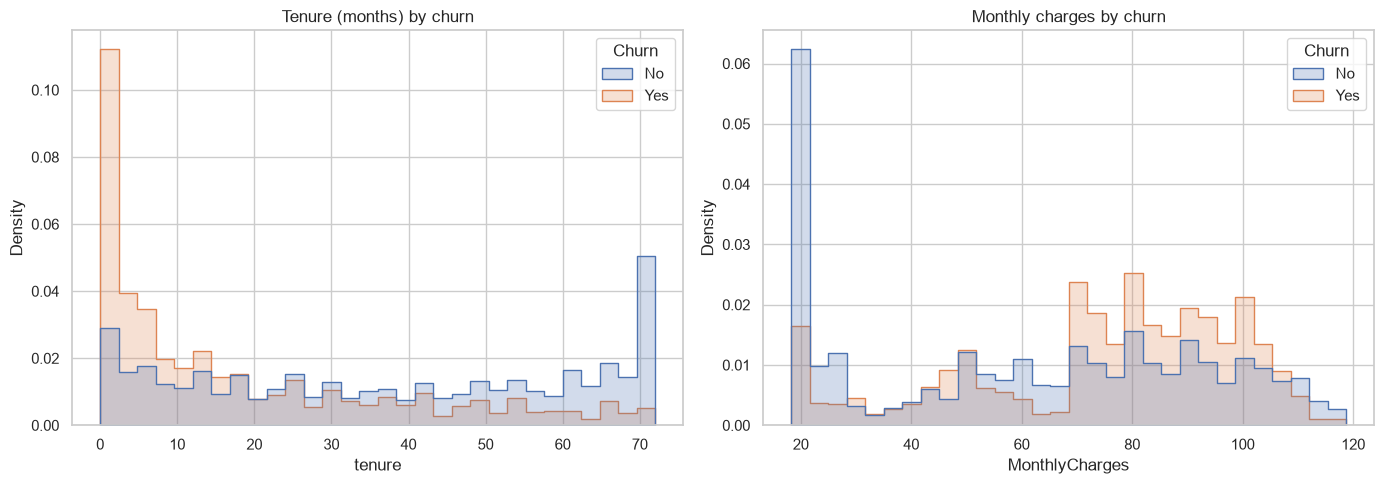

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x="tenure", hue="Churn", bins=30,
             stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set_title("Tenure (months) by churn")

sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=30,
             stat="density", common_norm=False, element="step", ax=axes[1])
axes[1].set_title("Monthly charges by churn")

plt.tight_layout()
plt.show()

In [25]:
df["tenure_group"] = pd.cut(df["tenure"],
                            bins=[-1, 6, 12, 24, 48, 72],
                            labels=["0-6", "7-12", "13-24", "25-48", "49-72"])

df.groupby("tenure_group", observed=True)["churn_flag"].mean().mul(100).round(1)

tenure_group
0-6      52.9
7-12     35.9
13-24    28.7
25-48    20.4
49-72     9.5
Name: churn_flag, dtype: float64

### Who churns? (tenure and charges)
- Customers with 0–6 months tenure have the highest churn rate at 52.9%, compared with 35.9% for 7–12 months, 28.7% for 13–24 months, 20.4% for 25–48 months, and only 9.5% for 49–72 months. This might be because new customers have not built loyalty to the company yet and may leave if they find better offers elsewhere.

- Customers with higher monthly charges tend to churn more than customers with lower monthly charges. This might be because expensive monthly bills make customers feel that the service is not worth the price, encouraging them to switch to cheaper providers.

- Overall, customers who have been with the company for a shorter time and pay higher monthly charges are more likely to leave. The company should focus on improving service quality and offering discounts to keep these customers.